<a href="https://colab.research.google.com/github/kashvis88/online-retail-sales-analysis/blob/main/Online_retail_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Environment and Data Acquistion

In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt



In [ ]:
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
online_retail = fetch_ucirepo(id=352)
df = online_retail.data.original.copy()
display(df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [ ]:
display(df.dtypes)

,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,object
UnitPrice,float64
CustomerID,float64
Country,object


In [ ]:
print("rows,columns:",df.shape)

rows,columns: (541909, 8)


#Data quality

In [ ]:
pd.DataFrame({
  "dtype":df.dtypes.astype(str),
  "missing_count":df.isna().sum(),
"unique_non_null":df.nunique(dropna=True)
})


,dtype,missing_count,unique_non_null
InvoiceNo,object,0,25900
StockCode,object,0,4070
Description,object,1454,4223
Quantity,int64,0,722
InvoiceDate,object,0,23260
UnitPrice,float64,0,1630
CustomerID,float64,135080,4372
Country,object,0,38


#Data Transformation

In [ ]:
def clean_sales(raw):
  data = raw.copy().drop_duplicates()
  data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"],errors="coerce")
  for col in ["Quantity","UnitPrice"]:
    data[col] = pd.to_numeric(data[col],errors="coerce")
  data = data.dropna(subset=["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"])
  valid = (data["Quantity"]>0)& (data["UnitPrice"]>0)
  data = data.loc[valid].copy()
  data["Revenue"] = data["Quantity"]*data["UnitPrice"]
  data["Month"] = data ["InvoiceDate"].dt.to_period("M")

  return data


In [ ]:
sales = clean_sales(df)
sales

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20,2011-12
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,2011-12
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011-12
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011-12


# KPI Scorecard

In [ ]:
kpis = {
    "Gross sales revenue (GBP)": sales["Revenue"].sum(),
"Unique number of invoices": sales["InvoiceNo"].nunique(),
"Unique number of customers": sales["CustomerID"].nunique(),
"Average order value (GBP)":sales["Revenue"].sum() / sales["InvoiceNo"].nunique(),
"Total units sold": sales["Quantity"].sum(),
    "Rows with known customer (%)": sales["CustomerID"].notna().mean() * 100,
}

pd.DataFrame({"KPI": list(kpis), "Value": list(kpis.values())})


,KPI,Value
0,Gross sales revenue (GBP),1.064211e+07
1,Unique number of invoices,1.996000e+04
2,Unique number of customers,4.338000e+03
3,Average order value (GBP),5.331719e+02
4,Total units sold,5.572420e+06
5,Rows with known customer (%),7.481586e+01


#Monthly Revenue Trends

In [ ]:
monthly = sales.groupby("Month")
monthly = sales.groupby("Month").agg(
  revenue = ('Revenue','sum'),
  orders = ('InvoiceNo','nunique'),
    units = ('Quantity','sum')
).reset_index()
monthly ["month_label"] = monthly["Month"].astype(str)
monthly

,Month,revenue,orders,units,month_label
0,2010-12,821452.730,1559,358019,2010-12
1,2011-01,689811.610,1086,387099,2011-01
2,2011-02,522545.560,1100,282934,2011-02
3,2011-03,716215.260,1454,376599,2011-03
4,2011-04,536968.491,1246,307953,2011-04
5,2011-05,769296.610,1681,395001,2011-05
6,2011-06,760547.010,1533,388511,2011-06
7,2011-07,718076.121,1475,399693,2011-07
8,2011-08,757841.380,1361,421020,2011-08
9,2011-09,1056435.192,1837,569573,2011-09


<Axes: xlabel='month_label', ylabel='revenue'>

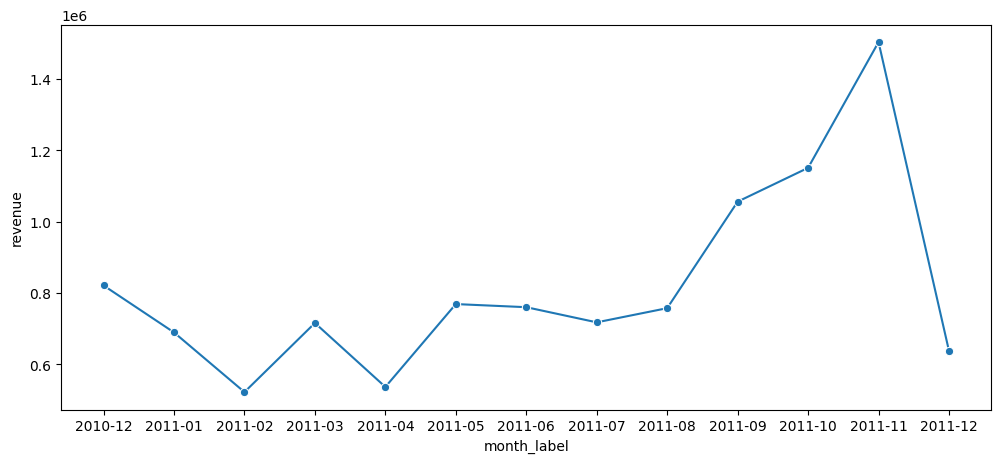

In [ ]:
fig,ax = plt.subplots(figsize = (12,5))
sns.lineplot(data=monthly, x='month_label', y='revenue', marker='o', ax=ax)

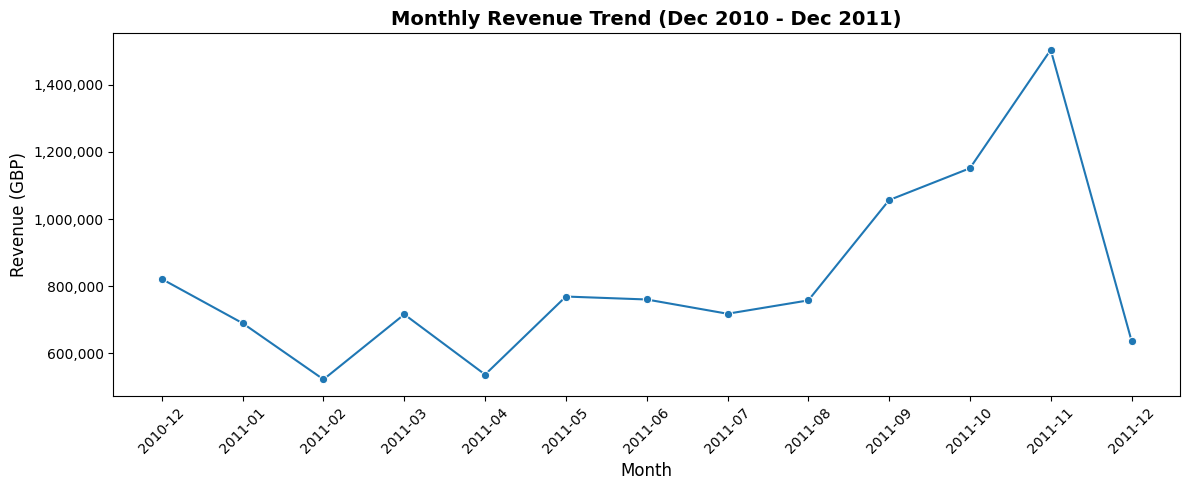

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly, x='month_label', y='revenue', marker='o', ax=ax)

# Set title and custom axis labels
ax.set_title('Monthly Revenue Trend (Dec 2010 - Dec 2011)', fontsize=14, fontweight='bold')
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Revenue (GBP)', fontsize=12)

# Rotate x-axis labels for better visibility
plt.xticks(rotation=45)

# Format y-axis values with commas for easier reading
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x:,.0f}"))

plt.tight_layout()
plt.show()

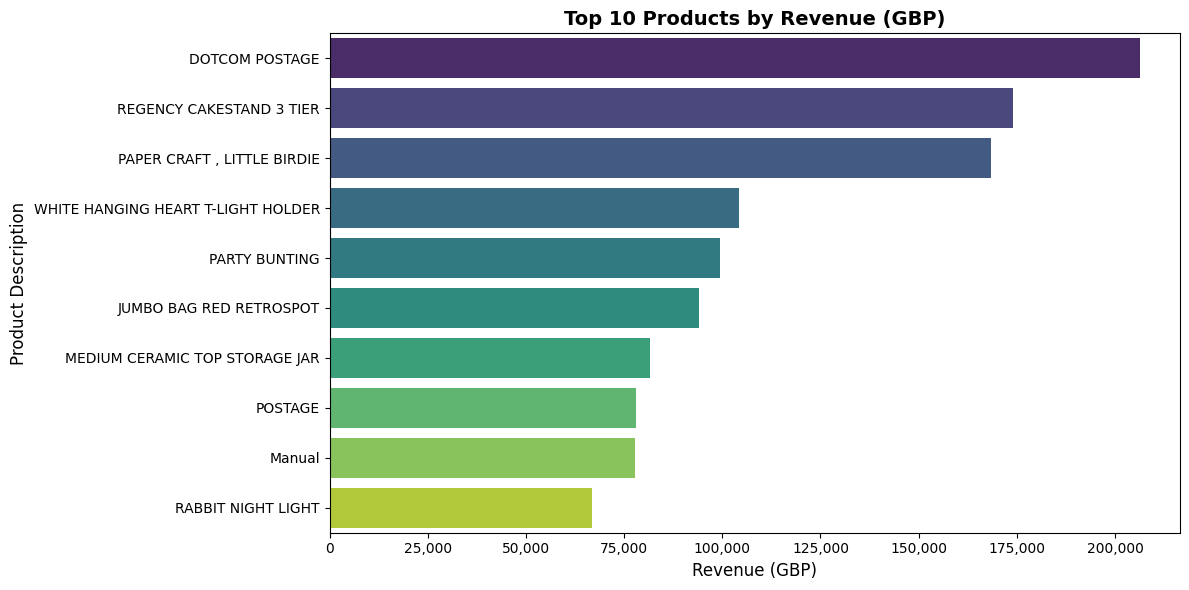

In [ ]:
# Group by product and calculate total revenue
top_products = sales.groupby(['StockCode', 'Description']).agg(
    total_revenue=('Revenue', 'sum'),
    total_quantity=('Quantity', 'sum')
).reset_index()

# Sort to get the top 10 products by revenue
top_10_products = top_products.sort_values(by='total_revenue', ascending=False).head(10)

# Create the bar chart
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=top_10_products,
    x='total_revenue',
    y='Description',
    hue='Description',
    palette='viridis',
    legend=False,
    ax=ax
)

# Set labels and title
ax.set_title('Top 10 Products by Revenue (GBP)', fontsize=14, fontweight='bold')
ax.set_xlabel('Revenue (GBP)', fontsize=12)
ax.set_ylabel('Product Description', fontsize=12)

# Format the x-axis values with commas for readability
ax.get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x:,.0f}"))

plt.tight_layout()
plt.show()

In [ ]:
# Calculate total revenue by country
country_revenue = sales.groupby('Country').agg(
    total_revenue=('Revenue', 'sum'),
    total_orders=('InvoiceNo', 'nunique'),
    total_quantity=('Quantity', 'sum')
).reset_index().sort_values(by='total_revenue', ascending=False)

# Display the top country breakdown
display(country_revenue.head(10))

,Country,total_revenue,total_orders,total_quantity
36,United Kingdom,9001744.094,18019,4646906
24,Netherlands,285446.340,94,200361
10,EIRE,283140.520,288,147007
14,Germany,228678.400,457,119154
13,France,209625.370,392,112060
0,Australia,138453.810,57,83891
31,Spain,61558.560,90,27933
33,Switzerland,57067.600,54,30617
3,Belgium,41196.340,98,23237
32,Sweden,38367.830,36,36078


In [ ]:
# Create interactive bar chart excluding the United Kingdom if it dominates heavily,
# or showing all. Let's create an interactive bar chart of top 10 countries (excluding UK if desired, or all).
# To give a clear picture of global distribution, we will plot the top 10 countries.
top_10_countries = country_revenue.head(10)

fig_country = px.bar(
    top_10_countries,
    x='total_revenue',
    y='Country',
    orientation='h',
    title='Top 10 Countries by Revenue (GBP)',
    labels={'total_revenue': 'Total Revenue (GBP)', 'Country': 'Country'},
    color='total_revenue',
    color_continuous_scale='Plasma'
)

fig_country.update_layout(
    yaxis={'categoryorder': 'total ascending'},
    xaxis_tickformat=',.0f',
    title_font_size=16,
    title_x=0.5,
    height=500
)

fig_country.update_xaxes(type='log',title='Total Revenue (GBP) - Log Scale')

fig_country.show()